# Relation ablation, LR version (Minh)

Which relation in G carries the signal? Each of the 28 G columns belongs to one of 6 relations
(follow, mention, reply, quote, url, hashtag; follow has 5 columns, the others 5 or 4).

- **Leave one out:** P + C + T + G, minus one relation's columns (6 runs). Drop = how much the model loses without it.
- **Add one:** P + C + T, plus one relation's columns (6 runs). Gain = what the relation adds on top of content.
- **Extra, relation alone:** one relation's columns only, no content (6 runs). Not asked for; cheap and shows the raw signal per relation.

Settings are `fusion_lr` from `p1.ipynb` and the fair baseline in `baselines.ipynb`: P, C and G standardized with train
statistics, T kept raw, `class_weight="balanced"`, C in {0.01, 0.1, 1, 10} chosen on validation PR-AUC, threshold from
`best_threshold`. Validation only; the test set is not used.

In [1]:
# 1. Setup (Colab or local)
import os, sys
if not os.path.exists("mgtab.py"):
    if "google.colab" in sys.modules:
        if not os.path.exists("sna-content-moderation"):
            !git clone -q https://github.com/ThSonDev/sna-content-moderation.git
        %cd sna-content-moderation
        !pip install -q -r requirements.txt
        !python install_pyg.py
    else:
        %cd ..
sys.path.insert(0, os.getcwd())

/home/minhubuntu/projects/sna-content-moderation


In [2]:
# 2. Download MGTAB (31 MB) into data/MGTAB, only once
import urllib.request, zipfile
if not os.path.exists("data/MGTAB/features.pt"):
    os.makedirs("data", exist_ok=True)
    url = "https://drive.usercontent.google.com/download?id=1gbWNOoU1JB8RrTu2a5j9KMNVa9wX72Fe&export=download&confirm=t"
    urllib.request.urlretrieve(url, "data/MGTAB.zip")
    zipfile.ZipFile("data/MGTAB.zip").extractall("data")

In [3]:
# 3. Load data and the shared split (never make your own split)
import numpy as np
from mgtab import load, relations, split, best_threshold, evaluate, RELATIONS
X, y, stance, E, T, W = load()
rel = relations(E, T, len(y))   # {"follow": (src, dst), ...}
train, val, test = split(y)     # test stays locked until the final run
print(X.shape, {r: len(s) for r, (s, d) in rel.items()})

(10199, 788) {'follow': 425863, 'mention': 110868, 'reply': 22327, 'quote': 20901, 'url': 263800, 'hashtag': 300000}


## Feature groups

In [4]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.preprocessing import StandardScaler
from features import feature_groups

groups, g_names = feature_groups(X, rel)   # G is cached in data/g_struct.npz after the first run
Z = {k: StandardScaler().fit(v[train]).transform(v) for k, v in groups.items() if k != "T"}  # train statistics only
Z["T"] = groups["T"]                                                                       # T raw, as in the baselines
cols = {r: [j for j, c in enumerate(g_names) if c.startswith(r + "_")] for r in RELATIONS}
assert sorted(sum(cols.values(), [])) == list(range(28)), "every G column belongs to exactly one relation"
content = np.hstack([Z["P"], Z["C"], Z["T"]])
{r: [g_names[j] for j in js] for r, js in cols.items()}

{'follow': [np.str_('follow_in_degree'),
  np.str_('follow_out_degree'),
  np.str_('follow_pagerank'),
  np.str_('follow_clustering'),
  np.str_('follow_kcore')],
 'mention': [np.str_('mention_in_degree'),
  np.str_('mention_out_degree'),
  np.str_('mention_pagerank'),
  np.str_('mention_clustering'),
  np.str_('mention_kcore')],
 'reply': [np.str_('reply_in_degree'),
  np.str_('reply_out_degree'),
  np.str_('reply_pagerank'),
  np.str_('reply_clustering'),
  np.str_('reply_kcore')],
 'quote': [np.str_('quote_in_degree'),
  np.str_('quote_out_degree'),
  np.str_('quote_pagerank'),
  np.str_('quote_clustering'),
  np.str_('quote_kcore')],
 'url': [np.str_('url_degree'),
  np.str_('url_pagerank'),
  np.str_('url_clustering'),
  np.str_('url_kcore')],
 'hashtag': [np.str_('hashtag_degree'),
  np.str_('hashtag_pagerank'),
  np.str_('hashtag_clustering'),
  np.str_('hashtag_kcore')]}

## Runs

In [5]:
def fusion_lr(F):
    best = None
    for C in [0.01, 0.1, 1, 10]:
        clf = LogisticRegression(C=C, class_weight="balanced", max_iter=5000).fit(F[train], y[train])
        s = clf.predict_proba(F[val])[:, 1]
        ap = average_precision_score(y[val], s)
        if best is None or ap > best[0]:
            best = (ap, C, s)
    _, C, s = best
    return {"C": C, **evaluate(y[val], s, best_threshold(y[val], s))}, s

def G_of(rs):
    return Z["G"][:, [j for r in rs for j in cols[r]]]

runs = {("reference", "all", "P+C+T+G"): np.hstack([content, Z["G"]]),
        ("reference", "none", "P+C+T"): content}
for r in RELATIONS:
    runs[("leave_one_out", r, f"P+C+T+G - {r}")] = np.hstack([content, G_of([x for x in RELATIONS if x != r])])
for r in RELATIONS:
    runs[("add_one", r, f"P+C+T + {r}")] = np.hstack([content, G_of([r])])
for r in RELATIONS:
    runs[("relation_alone", r, f"G[{r}] only")] = G_of([r])

rows, scores = [], {}
for (kind, r, name), F in runs.items():
    m, scores[name] = fusion_lr(F)   # validation scores kept for the bootstrap below
    rows.append({"ablation": kind, "relation": r, "model": name, "n_features": F.shape[1], **m})
    print(f"{name:28s} PR-AUC {rows[-1]['pr_auc']:.4f}")
res = pd.DataFrame(rows)

P+C+T+G                      PR-AUC 0.9153


P+C+T                        PR-AUC 0.8781


P+C+T+G - follow             PR-AUC 0.9085


P+C+T+G - mention            PR-AUC 0.9142


P+C+T+G - reply              PR-AUC 0.9146


P+C+T+G - quote              PR-AUC 0.9141


... (10 outputs left out)

G[reply] only                PR-AUC 0.3644


G[quote] only                PR-AUC 0.3172


G[url] only                  PR-AUC 0.3098


G[hashtag] only              PR-AUC 0.3854


## Results

`delta_pr_auc` / `delta_macro_f1`: change against the reference of the same block (leave one out vs P+C+T+G,
add one vs P+C+T). For "relation alone" the delta is against P+C+T and only shows scale.

`delta_pr_auc_ci_low/high`: 95% paired-bootstrap interval of the PR-AUC change (validation accounts resampled).

In [6]:
ref = {"leave_one_out": "P+C+T+G", "add_one": "P+C+T", "relation_alone": "P+C+T", "reference": "P+C+T"}
by_name = res.set_index("model")
res["delta_pr_auc"] = [row.pr_auc - by_name.loc[ref[row.ablation], "pr_auc"] for row in res.itertuples()]
res["delta_macro_f1"] = [row.macro_f1 - by_name.loc[ref[row.ablation], "macro_f1"] for row in res.itertuples()]

# Paired bootstrap over validation accounts (1000 resamples, same resample for both models): 95% CI of delta PR-AUC.
# Only the scores are resampled; C and the threshold stay fixed. If the CI contains 0, the difference is noise.
rng = np.random.default_rng(42)
boots = [rng.choice(len(val), len(val)) for _ in range(1000)]
yv = y[val]
def ci(a, b):
    d = [average_precision_score(yv[i], scores[a][i]) - average_precision_score(yv[i], scores[b][i]) for i in boots]
    return np.percentile(d, [2.5, 97.5])
lo_hi = [ci(row.model, ref[row.ablation]) if row.ablation in ("leave_one_out", "add_one") or row.model == "P+C+T+G"
         else (np.nan, np.nan) for row in res.itertuples()]
res["delta_pr_auc_ci_low"], res["delta_pr_auc_ci_high"] = zip(*lo_hi)
res.to_csv("results/relations.csv", index=False)
show = ["model", "n_features", "C", "pr_auc", "delta_pr_auc", "delta_pr_auc_ci_low", "delta_pr_auc_ci_high", "macro_f1", "delta_macro_f1", "accuracy", "p@100", "p@200"]
for kind in ["reference", "leave_one_out", "add_one", "relation_alone"]:
    part = res[res.ablation == kind][show]
    if kind != "reference":
        part = part.sort_values("delta_pr_auc", ascending=kind != "leave_one_out")
    print(kind); display(part.round(4))

reference


,model,n_features,C,pr_auc,delta_pr_auc,delta_pr_auc_ci_low,delta_pr_auc_ci_high,macro_f1,delta_macro_f1,accuracy,p@100,p@200
0,P+C+T+G,816,0.1,0.9153,0.0373,0.0201,0.0571,0.9059,0.0201,0.9229,0.97,0.950
1,P+C+T,788,10.0,0.8781,0.0000,NaN,NaN,0.8858,0.0000,0.9072,0.96,0.915


leave_one_out


,model,n_features,C,pr_auc,delta_pr_auc,delta_pr_auc_ci_low,delta_pr_auc_ci_high,macro_f1,delta_macro_f1,accuracy,p@100,p@200
4,P+C+T+G - reply,811,0.1,0.9146,-0.0008,-0.0036,0.0022,0.9066,0.0007,0.9235,0.97,0.940
3,P+C+T+G - mention,811,0.1,0.9142,-0.0011,-0.0038,0.0013,0.9050,-0.0009,0.9229,0.97,0.940
5,P+C+T+G - quote,811,0.1,0.9141,-0.0013,-0.0034,0.0005,0.9049,-0.0010,0.9222,0.97,0.945
6,P+C+T+G - url,812,0.1,0.9128,-0.0025,-0.0064,0.0008,0.9052,-0.0007,0.9216,0.97,0.935
2,P+C+T+G - follow,811,0.1,0.9085,-0.0068,-0.0141,-0.0006,0.8981,-0.0078,0.9196,0.98,0.945
7,P+C+T+G - hashtag,812,0.1,0.9013,-0.0140,-0.0249,-0.0032,0.9002,-0.0057,0.9196,0.95,0.925


add_one


,model,n_features,C,pr_auc,delta_pr_auc,delta_pr_auc_ci_low,delta_pr_auc_ci_high,macro_f1,delta_macro_f1,accuracy,p@100,p@200
10,P+C+T + reply,793,10.0,0.8861,0.0080,0.0010,0.0157,0.8876,0.0018,0.9111,0.97,0.930
11,P+C+T + quote,793,10.0,0.8862,0.0082,0.0029,0.0145,0.8848,-0.0010,0.9046,0.96,0.925
12,P+C+T + url,792,0.1,0.8870,0.0089,-0.0082,0.0263,0.8909,0.0051,0.9118,0.96,0.925
9,P+C+T + mention,793,0.1,0.8897,0.0116,-0.0040,0.0296,0.8977,0.0118,0.9190,0.95,0.925
8,P+C+T + follow,793,0.1,0.8911,0.0130,-0.0033,0.0334,0.9058,0.0200,0.9229,0.94,0.915
13,P+C+T + hashtag,792,0.1,0.8957,0.0176,0.0008,0.0355,0.9007,0.0149,0.9176,0.96,0.935


relation_alone


,model,n_features,C,pr_auc,delta_pr_auc,delta_pr_auc_ci_low,delta_pr_auc_ci_high,macro_f1,delta_macro_f1,accuracy,p@100,p@200
18,G[url] only,4,10.0,0.3098,-0.5683,NaN,NaN,0.5548,-0.3310,0.6451,0.33,0.345
17,G[quote] only,5,10.0,0.3172,-0.5609,NaN,NaN,0.4870,-0.3988,0.4902,0.22,0.185
16,G[reply] only,5,1.0,0.3644,-0.5137,NaN,NaN,0.5535,-0.3323,0.5562,0.43,0.460
19,G[hashtag] only,4,10.0,0.3854,-0.4927,NaN,NaN,0.5822,-0.3037,0.6902,0.57,0.455
15,G[mention] only,5,1.0,0.4314,-0.4467,NaN,NaN,0.6235,-0.2623,0.7229,0.53,0.485
14,G[follow] only,5,0.1,0.5475,-0.3306,NaN,NaN,0.7049,-0.1809,0.7464,0.60,0.595


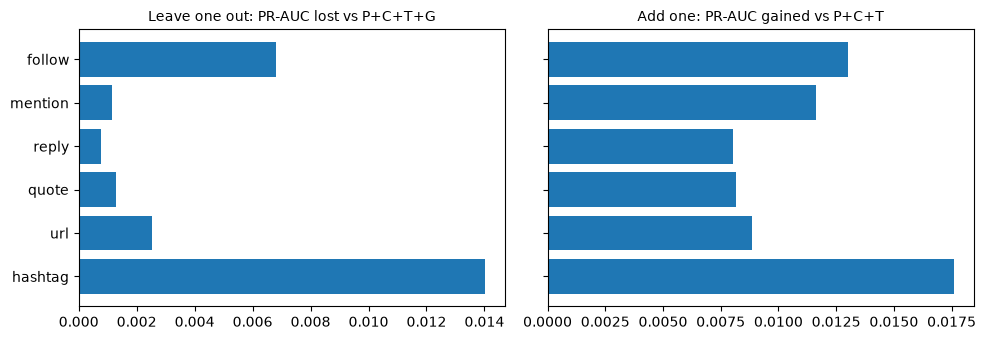

In [7]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for a, kind, title in [(ax[0], "leave_one_out", "Leave one out: PR-AUC lost vs P+C+T+G"),
                       (ax[1], "add_one", "Add one: PR-AUC gained vs P+C+T")]:
    part = res[res.ablation == kind].set_index("relation").reindex(RELATIONS)
    v = -part.delta_pr_auc if kind == "leave_one_out" else part.delta_pr_auc
    a.barh(RELATIONS, v); a.set_title(title, fontsize=10); a.axvline(0, color="k", lw=0.5)
ax[0].invert_yaxis(); plt.tight_layout(); plt.show()

## Findings (validation, one split)

1. **G adds +0.037 PR-AUC over P + C + T** (0.878 → 0.915, 95% CI +0.020 to +0.057), so the graph gain is real after
   the 4 counts are in the baseline. Same numbers as `baselines.csv`.
2. **Only hashtag and follow cannot be replaced.** Leaving out hashtag costs −0.014 PR-AUC (CI −0.025 to −0.003),
   follow −0.007 (CI −0.014 to −0.001). Leaving out mention, reply, quote or url costs ≤ 0.003 and every CI contains 0:
   the other relations carry the same information.
3. **Every relation helps on its own, but they overlap.** Added alone to P + C + T, the gains are hashtag +0.018,
   follow +0.013, mention +0.012, url +0.009, quote +0.008, reply +0.008. They sum to +0.067, almost twice the +0.037
   of all six together, so much of the signal is shared (mostly activity: degree and PageRank).
   Only hashtag, reply and quote have CIs above 0; follow, mention and url have wide CIs, partly because their best C
   (0.1) differs from the P + C + T reference (10).
4. **Strong alone ≠ useful with content.** Without content, follow is the best single relation (PR-AUC 0.548) and
   hashtag is weak (0.385). With content, hashtag is the most useful: it adds what text and profile miss, while much
   of follow's signal probably overlaps with the follower/friend counts in C.
5. **For the RGCN:** keep follow and hashtag as their own edge types; mention, reply, quote and url can be kept, but
   expect little from each, so they are candidates to merge or drop if training is slow or unstable (check in A5).
   The hashtag and url graphs are co-occurrence graphs (undirected, hashtag has exactly 300,000 edges), so they behave
   differently from follow; a relation-specific weight per edge type fits this better than one merged graph.

Caveats: one split, 1,530 validation accounts (412 bots); differences below ~0.003 PR-AUC are within noise. LR on
hand-made graph features only; the RGCN version (A5) may rank relations differently.